In [ ]:
# ------------------------------------------------------------
# CELL 0 — mount Google Drive
# ------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ------------------------------------------------------------
# CELL 1 — install any missing packages (skip if already installed)
# ------------------------------------------------------------
!pip install shap timm --quiet

Found 5 class folders: ['Basal_Cell_Carcinoma', 'Eczema', 'Keratosis', 'Melanoma', 'Tinea']

  Basal_Cell_Carcinoma: 8 -> background/, 3 -> test/
  Eczema: 8 -> background/, 3 -> test/
  Keratosis: 8 -> background/, 3 -> test/
  Melanoma: 8 -> background/, 3 -> test/
  Tinea: 8 -> background/, 3 -> test/

Done. New folder created on Drive at: /content/drive/MyDrive/IPD/XAI
  Background: /content/drive/MyDrive/IPD/XAI/background
  Test:       /content/drive/MyDrive/IPD/XAI/test


In [ ]:
# ------------------------------------------------------------
# CELL 2 — clone the repo (code only, checkpoints are gitignored)
# ------------------------------------------------------------
!git clone https://github.com/Jmanav/SkinSure.git /content/SkinSure



In [ ]:
import subprocess
result = subprocess.run(['find', '/content/drive/MyDrive', '-iname', '*weights_skinsure*'], capture_output=True, text=True)
print(result.stdout)aaaaaaa

/content/drive/MyDrive/weights_skinsure



In [ ]:
import os
for f in os.listdir("/content/drive/MyDrive/weights_skinsure"):
    print(f)

best_efficientnet_b1_5cls.pth
efficientnet_b1_5cls_skin.pth
convnext_tiny_5cls_skin.pth
best_swin_tiny_5cls.pth
swin_tiny_5cls_skin.pth
best_convnext_tiny_5cls.pth


In [ ]:
# MAIN SHAP

In [ ]:
# ------------------------------------------------------------
# CELL 1 — mount drive
# ------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ------------------------------------------------------------
# CELL 2 — clone the repo (code only, checkpoints are gitignored)
# ------------------------------------------------------------
!git clone https://github.com/Jmanav/SkinSure.git /content/SkinSure

Cloning into '/content/SkinSure'...
remote: Enumerating objects: 142, done.
remote: Counting objects: 100% (142/142), done.
remote: Compressing objects: 100% (83/83), done.
remote: Total 142 (delta 50), reused 127 (delta 37), pack-reused 0 (from 0)
Receiving objects: 100% (142/142), 226.99 KiB | 2.91 MiB/s, done.
Resolving deltas: 100% (50/50), done.


In [ ]:
# ------------------------------------------------------------
# CELL 3 — install deps
# ------------------------------------------------------------
!pip install -q shap timm

In [ ]:
# ------------------------------------------------------------
# CELL 4 — imports + config
# ------------------------------------------------------------
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import torch
import shap

REPO_ROOT = "/content/SkinSure"
sys.path.insert(0, REPO_ROOT)

CHECKPOINTS = {
    "efficientnet_b1": "/content/drive/MyDrive/weights_skinsure/efficientnet_b1_5cls_skin.pth",
    "convnext_tiny": "/content/drive/MyDrive/weights_skinsure/convnext_tiny_5cls_skin.pth",
}

IMAGE_SIZE = 224
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]

# From the auto-split you already ran
BACKGROUND_DIR = "/content/drive/MyDrive/IPD/XAI/background"
TEST_DIR = "/content/drive/MyDrive/IPD/XAI/test"

OUTPUT_DIR = "/content/drive/MyDrive/IPD/XAI/shap_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
VALID_EXTS = (".png", ".jpg", ".jpeg")



In [ ]:

# ------------------------------------------------------------
# CELL 5 — image loading (walks class subfolders)
# ------------------------------------------------------------
from PIL import Image

def load_images_from_class_dirs(root_dir, image_size):
    images, paths, labels = [], [], []
    class_names = sorted(
        d for d in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, d))
    )
    for cls in class_names:
        cls_dir = os.path.join(root_dir, cls)
        for fname in sorted(os.listdir(cls_dir)):
            if not fname.lower().endswith(VALID_EXTS):
                continue
            p = os.path.join(cls_dir, fname)
            img = Image.open(p).convert("RGB").resize((image_size, image_size))
            images.append(np.array(img, dtype=np.float32) / 255.0)
            paths.append(p)
            labels.append(cls)
    return np.stack(images), paths, labels


def make_preprocess_fn():
    mean = torch.tensor(NORM_MEAN, device=DEVICE).view(1, 3, 1, 1)
    std = torch.tensor(NORM_STD, device=DEVICE).view(1, 3, 1, 1)
    def preprocess(images_np):
        t = torch.tensor(images_np, device=DEVICE).permute(0, 3, 1, 2).float()
        return (t - mean) / std
    return preprocess


In [ ]:
# ------------------------------------------------------------
# CELL 6 — model loading (reuses teammate's loader functions)
# ------------------------------------------------------------
def load_model(model_key):
    ckpt_path = CHECKPOINTS[model_key]
    if model_key == "efficientnet_b1":
        from src.models.efficientnet import load_efficientnet_b1
        model, classes = load_efficientnet_b1(ckpt_path, DEVICE)
    elif model_key == "convnext_tiny":
        from src.models.convnext import load_convnext_tiny
        model, classes = load_convnext_tiny(ckpt_path, DEVICE)
    else:
        raise ValueError(model_key)
    model.eval()
    return model, classes



In [ ]:
# ------------------------------------------------------------
# CELL 7 — SHAP + smoother, publication-friendly plotting
# ------------------------------------------------------------
from scipy.ndimage import gaussian_filter

def run_shap_for_model(model_key, background_np, test_np):
    print(f"\n=== {model_key} ===")
    model, class_names = load_model(model_key)
    preprocess = make_preprocess_fn()

    background_tensor = preprocess(background_np)
    test_tensor = preprocess(test_np)

    # local_smoothing reduces random noise in the SHAP calculation itself
    explainer = shap.GradientExplainer(model, background_tensor, local_smoothing=0.5)
    raw_shap_values, indexes = explainer.shap_values(test_tensor, ranked_outputs=1, nsamples=150)

    if isinstance(raw_shap_values, list):
        sv = raw_shap_values[0]
    else:
        sv = raw_shap_values[..., 0]

    shap_values = np.transpose(sv, (0, 2, 3, 1))  # (N, H, W, C)
    pred_names = np.array([[class_names[i] for i in row] for row in indexes.cpu().numpy()])
    return shap_values, pred_names


def save_shap_plots(model_key, shap_values, test_np, pred_names, true_labels, test_paths):
    out_dir = os.path.join(OUTPUT_DIR, model_key)
    os.makedirs(out_dir, exist_ok=True)

    for i, path in enumerate(test_paths):
        fname = os.path.splitext(os.path.basename(path))[0]

        # collapse to single heatmap and lightly smooth JUST for display
        heatmap = shap_values[i].sum(axis=-1)
        heatmap_smooth = gaussian_filter(heatmap, sigma=3)
        vmax = np.abs(heatmap_smooth).max()

        fig, axes = plt.subplots(1, 3, figsize=(12, 4))

        axes[0].imshow(test_np[i])
        axes[0].set_title(f"True: {true_labels[i]}\nPred: {pred_names[i][0]}")
        axes[0].axis("off")

        im = axes[1].imshow(heatmap_smooth, cmap="bwr", vmin=-vmax, vmax=vmax)
        axes[1].set_title(f"SHAP ({model_key})")
        axes[1].axis("off")
        plt.colorbar(im, ax=axes[1], fraction=0.046)

        # overlay: original image with heatmap blended on top, semi-transparent
        axes[2].imshow(test_np[i])
        axes[2].imshow(heatmap_smooth, cmap="bwr", vmin=-vmax, vmax=vmax, alpha=0.5)
        axes[2].set_title("Overlay")
        axes[2].axis("off")

        out_path = os.path.join(out_dir, f"shap_{true_labels[i]}_{fname}.png")
        plt.savefig(out_path, bbox_inches="tight", dpi=150)
        plt.close()
        print(f"Saved -> {out_path}")

In [ ]:
import numpy as np
import torch.serialization
torch.serialization.add_safe_globals([np._core.multiarray.scalar])

In [ ]:
import torch
import functools
torch.load = functools.partial(torch.load, weights_only=False)

In [ ]:
# ------------------------------------------------------------
# CELL 8 (UPDATED) — run everything, but also save shap_values
# per model so the deletion test in Cell 9 can reuse them
# ------------------------------------------------------------
background_np, _, _ = load_images_from_class_dirs(BACKGROUND_DIR, IMAGE_SIZE)
test_np, test_paths, true_labels = load_images_from_class_dirs(TEST_DIR, IMAGE_SIZE)
print(f"Background: {len(background_np)} images | Test: {len(test_np)} images")

all_shap_values = {}   # model_key -> shap_values array (N, H, W, 3)
all_pred_names = {}    # model_key -> predicted class names

for model_key in CHECKPOINTS:
    shap_values, pred_names = run_shap_for_model(model_key, background_np, test_np)
    save_shap_plots(model_key, shap_values, test_np, pred_names, true_labels, test_paths)
    all_shap_values[model_key] = shap_values
    all_pred_names[model_key] = pred_names

print("\nDone. Outputs saved under:", OUTPUT_DIR)



Background: 40 images | Test: 15 images

=== efficientnet_b1 ===
✓ EfficientNet-B1 | val=87.69% test=85.11% | mel_sens=98.6%
Saved -> /content/drive/MyDrive/IPD/XAI/shap_outputs/efficientnet_b1/shap_Basal_Cell_Carcinoma_ISIC_0065249.png
Saved -> /content/drive/MyDrive/IPD/XAI/shap_outputs/efficientnet_b1/shap_Basal_Cell_Carcinoma_ISIC_0071603.png
Saved -> /content/drive/MyDrive/IPD/XAI/shap_outputs/efficientnet_b1/shap_Basal_Cell_Carcinoma_ISIC_0073081.png
Saved -> /content/drive/MyDrive/IPD/XAI/shap_outputs/efficientnet_b1/shap_Eczema_6_29.png
Saved -> /content/drive/MyDrive/IPD/XAI/shap_outputs/efficientnet_b1/shap_Eczema_IMG20240403112731.png
Saved -> /content/drive/MyDrive/IPD/XAI/shap_outputs/efficientnet_b1/shap_Eczema_IMG_20230531_124822_1.png
Saved -> /content/drive/MyDrive/IPD/XAI/shap_outputs/efficientnet_b1/shap_Keratosis_ISIC_0062717.png
Saved -> /content/drive/MyDrive/IPD/XAI/shap_outputs/efficientnet_b1/shap_Keratosis_ISIC_0071952.png
Saved -> /content/drive/MyDrive/IPD/X


DELETION TEST (AOPC) RESULTS
✓ EfficientNet-B1 | val=87.69% test=85.11% | mel_sens=98.6%

efficientnet_b1:
  AOPC (higher = more faithful explanation) = 0.4990
  Confidence curve (0% -> 100% pixels removed): ['0.873', '0.648', '0.512', '0.493', '0.413', '0.328', '0.300', '0.293', '0.299', '0.240', '0.216']
✓ ConvNeXt-Tiny | val=75.57% test=71.35% | mel_sens=98.6%

convnext_tiny:
  AOPC (higher = more faithful explanation) = 0.3574
  Confidence curve (0% -> 100% pixels removed): ['0.724', '0.661', '0.565', '0.467', '0.370', '0.355', '0.332', '0.273', '0.246', '0.230', '0.171']
✓ EfficientNet-B1 | val=87.69% test=85.11% | mel_sens=98.6%
✓ ConvNeXt-Tiny | val=75.57% test=71.35% | mel_sens=98.6%


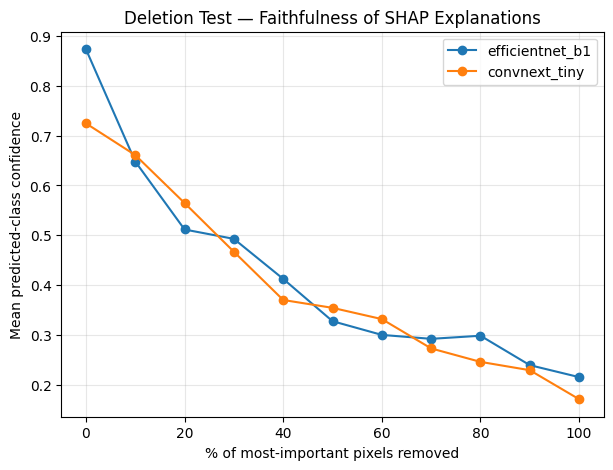


Saved deletion curve plot -> /content/drive/MyDrive/IPD/XAI/shap_outputs/deletion_test_curve.png


In [ ]:
# ------------------------------------------------------------
# CELL 9 — Deletion Test (AOPC) — quantitative faithfulness metric
# ------------------------------------------------------------
"""
What this measures:
Ranks pixels by SHAP importance, then progressively blanks out the most
important pixels first and watches how fast the model's confidence in its
predicted class drops. A bigger, faster drop means the explanation
correctly identified pixels the model actually depends on -- i.e. the
explanation is "faithful" to the model's real behavior.

Output: one AOPC (Area Over the Perturbation Curve) number per model.
Higher AOPC = more faithful explanation. This is the standard quantitative
metric used in XAI papers for exactly this kind of evaluation.
"""

import torch.nn.functional as F

DELETION_STEPS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]  # fraction of pixels removed

def deletion_test_for_model(model_key, shap_values, test_np, background_np):
    model, class_names = load_model(model_key)
    preprocess = make_preprocess_fn()

    # baseline replacement value = mean of the background set (a "neutral" pixel value)
    baseline_pixel = background_np.mean(axis=(0, 1, 2))  # shape (3,)

    all_curves = []  # one confidence-curve per test image

    for i in range(len(test_np)):
        img = test_np[i].copy()  # (H, W, 3), values in [0,1]

        # importance per pixel = summed absolute SHAP value across R,G,B
        importance = np.abs(shap_values[i]).sum(axis=-1)  # (H, W)
        flat_order = np.argsort(-importance.flatten())    # indices sorted by importance, descending

        h, w = importance.shape
        total_pixels = h * w

        # get the original prediction (class index with highest probability) once
        with torch.no_grad():
            inp = preprocess(img[None, ...])
            orig_probs = F.softmax(model(inp), dim=1)[0]
            target_class = int(torch.argmax(orig_probs))

        confidences = []
        for frac in DELETION_STEPS:
            n_remove = int(total_pixels * frac)
            modified = img.copy()
            if n_remove > 0:
                remove_idx = flat_order[:n_remove]
                rows, cols = np.unravel_index(remove_idx, (h, w))
                modified[rows, cols, :] = baseline_pixel  # blank out top-importance pixels

            with torch.no_grad():
                inp = preprocess(modified[None, ...])
                probs = F.softmax(model(inp), dim=1)[0]
                confidences.append(float(probs[target_class]))

        all_curves.append(confidences)

    all_curves = np.array(all_curves)  # (N_test, len(DELETION_STEPS))
    mean_curve = all_curves.mean(axis=0)

    # AOPC = average drop in confidence from the original (0% removed) across all steps
    aopc = float(np.mean(mean_curve[0] - mean_curve[1:]))

    return aopc, mean_curve


print("\n" + "=" * 50)
print("DELETION TEST (AOPC) RESULTS")
print("=" * 50)

aopc_results = {}
for model_key in CHECKPOINTS:
    aopc, curve = deletion_test_for_model(model_key, all_shap_values[model_key], test_np, background_np)
    aopc_results[model_key] = aopc
    print(f"\n{model_key}:")
    print(f"  AOPC (higher = more faithful explanation) = {aopc:.4f}")
    print(f"  Confidence curve (0% -> 100% pixels removed): {['%.3f' % c for c in curve]}")

# Optional: plot the deletion curves for both models on one graph
plt.figure(figsize=(7, 5))
for model_key in CHECKPOINTS:
    _, curve = deletion_test_for_model(model_key, all_shap_values[model_key], test_np, background_np)
    plt.plot([int(f * 100) for f in DELETION_STEPS], curve, marker="o", label=model_key)
plt.xlabel("% of most-important pixels removed")
plt.ylabel("Mean predicted-class confidence")
plt.title("Deletion Test — Faithfulness of SHAP Explanations")
plt.legend()
plt.grid(alpha=0.3)
curve_path = os.path.join(OUTPUT_DIR, "deletion_test_curve.png")
plt.savefig(curve_path, bbox_inches="tight", dpi=150)
plt.show()
print(f"\nSaved deletion curve plot -> {curve_path}")









In [ ]:
aopc_report_path = os.path.join(OUTPUT_DIR, "aopc_results.txt")
with open(aopc_report_path, "w") as f:
    f.write("Deletion Test (AOPC) Results\n")
    f.write("=" * 40 + "\n\n")
    for model_key, aopc in aopc_results.items():
        f.write(f"{model_key}: AOPC = {aopc:.4f}\n")

print(f"Saved AOPC report -> {aopc_report_path}")

Saved AOPC report -> /content/drive/MyDrive/IPD/XAI/shap_outputs/aopc_results.txt


In [ ]:
# ------------------------------------------------------------
# Count images per class + total, in the IPD 5 Diseases dataset
# ------------------------------------------------------------
import os

DATASET_ROOT = "/content/drive/MyDrive/IPD/IPD 5 Diseases Datasets"
VALID_EXTS = (".png", ".jpg", ".jpeg")

class_dirs = sorted(
    d for d in os.listdir(DATASET_ROOT)
    if os.path.isdir(os.path.join(DATASET_ROOT, d))
)

total = 0
print(f"{'Class':<30} {'Count'}")
print("-" * 40)
for cls in class_dirs:
    cls_path = os.path.join(DATASET_ROOT, cls)
    count = sum(
        1 for f in os.listdir(cls_path) if f.lower().endswith(VALID_EXTS)
    )
    total += count
    print(f"{cls:<30} {count}")

print("-" * 40)
print(f"{'TOTAL':<30} {total}")


Class                          Count
----------------------------------------
Basal_Cell_Carcinoma           3372
Eczema                         1788
Keratosis                      2380
Melanoma                       5808
Tinea                          1150
----------------------------------------
TOTAL                          14498
